# BiLSTM Multi-Task Classification for Citizen Complaints (with Sentiment-Enhanced Severity)

This notebook replaces the XLM-RoBERTa encoder with a **BiLSTM** encoder. Everything else is kept: the preprocessing, the sentiment-based severity adjustment, the focal loss and weighted sampling for class imbalance, the three task heads (primary category, subcategory, severity), and the evaluation and plots.

Changes from the XLM-R version:
- **Tokenization** still uses the XLM-R SentencePiece tokenizer, so Hindi, Hinglish and English subwords are handled the same way. Only the tokenizer is loaded, not the 270M-parameter model.
- **Vocabulary** is compacted to subword ids seen in the training set (min frequency 2). Dev and test tokens that were never seen in training map to `<UNK>`.
- **Encoder**: embedding layer, then a 2-layer bidirectional LSTM. The sentence vector is mean-pooled concatenated with max-pooled over valid tokens, instead of the `[CLS]` vector.
- **Embedding init** (optional): `USE_PRETRAINED_EMBEDDINGS = True` copies XLM-R's input embedding rows for the kept tokens. This downloads the XLM-R weights once but does not use them for anything else. Set it to `False` for purely random embeddings.
- **Training**: AdamW at 1e-3 with cosine warmup, 30 epochs with early stopping, and gradient clipping. These are standard BiLSTM settings. XLM-R's 2e-5 is too small for a randomly initialized recurrent model.
- **Security**: the hard-coded Hugging Face token has been removed. Set the `HF_TOKEN` environment variable instead. The token that was in the original notebook should be revoked, because it was saved in plain text.

In [1]:
# ============================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP
# ============================================================================
import os
import warnings
warnings.filterwarnings('ignore')

import json
import pickle
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from scipy.stats import pearsonr

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from transformers import AutoTokenizer, AutoModel, get_cosine_schedule_with_warmup

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, balanced_accuracy_score,
    cohen_kappa_score, matthews_corrcoef, precision_recall_fscore_support
)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Using device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

PyTorch version: 2.6.0+cu126
CUDA available: True
Using device: cuda


In [2]:
# ============================================================================
# CELL 2: CONFIGURATION
# ============================================================================
class Config:
    """Configuration for the BiLSTM multi-task complaint classifier"""

    # Tokenizer / embeddings
    TOKENIZER_NAME = "xlm-roberta-base"   # subword tokenizer (and embedding source if pretrained)
    USE_PRETRAINED_EMBEDDINGS = True      # init from XLM-R input embeddings for kept tokens
    EMBED_DIM = 300                       # used only when USE_PRETRAINED_EMBEDDINGS = False
    MIN_FREQ = 2                          # min training-set frequency for a token to enter the vocab
    MAX_LENGTH = 128

    # BiLSTM encoder
    LSTM_HIDDEN = 256                     # per direction
    LSTM_LAYERS = 2
    LSTM_DROPOUT = 0.3
    DROPOUT = 0.3

    # Optimisation
    BATCH_SIZE = 32
    EPOCHS = 30
    LEARNING_RATE = 1e-3
    WEIGHT_DECAY = 1e-4
    WARMUP_RATIO = 0.05
    CLIP_NORM = 1.0
    EARLY_STOP_PATIENCE = 7

    # Imbalance handling (same as the XLM-R version)
    USE_WEIGHTED_SAMPLER = True
    USE_FOCAL_LOSS = True
    FOCAL_ALPHA = 0.25
    FOCAL_GAMMA = 2.0
    SEVERITY_LOSS_WEIGHT = 0.5

    # Data paths
    DATA_DIR = "dataset"
    TRAIN_PATH = f"{DATA_DIR}/train/train.csv"
    DEV_PATH = f"{DATA_DIR}/dev/dev.csv"
    TEST_PATH = f"{DATA_DIR}/test/test.csv"

    # Output directories
    BASE_DIR = "bilstm_results"
    MODEL_DIR = f"{BASE_DIR}/models"
    VISUALIZATION_DIR = f"{BASE_DIR}/visualizations"
    LOG_DIR = f"{BASE_DIR}/logs"
    RESULTS_DIR = f"{BASE_DIR}/results"

    for _d in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, LOG_DIR, RESULTS_DIR]:
        os.makedirs(_d, exist_ok=True)

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42
    # Set the HF_TOKEN environment variable rather than hard-coding it
    HF_TOKEN = os.environ.get("HF_TOKEN")

print(f"Device: {Config.DEVICE}")
print(f"Results will be saved to: {Config.BASE_DIR}")
print(f"Encoder: BiLSTM ({Config.LSTM_LAYERS} layers x {Config.LSTM_HIDDEN} per direction)")

Device: cuda
Results will be saved to: bilstm_results
Encoder: BiLSTM (2 layers x 256 per direction)


In [3]:
# ============================================================================
# CELL 3: DATA LOADING WITH IMBALANCE ANALYSIS
# ============================================================================

class DataLoaderWithImbalance:
    """Load data and analyze class imbalance"""
    
    def __init__(self):
        self.train_df = None
        self.dev_df = None
        self.test_df = None
        self.class_weights = {}
        
    def load_data(self):
        """Load train, dev, test datasets"""
        print("Loading datasets...")
        
        self.train_df = pd.read_csv(Config.TRAIN_PATH)
        self.dev_df = pd.read_csv(Config.DEV_PATH)
        self.test_df = pd.read_csv(Config.TEST_PATH)
        
        print(f"Train samples: {len(self.train_df)}")
        print(f"Dev samples: {len(self.dev_df)}")
        print(f"Test samples: {len(self.test_df)}")
        
        return self.train_df, self.dev_df, self.test_df
    
    def analyze_imbalance(self, df, label_col, title=""):
        """Analyze and visualize class imbalance"""
        class_counts = df[label_col].value_counts()
        class_percentages = df[label_col].value_counts(normalize=True) * 100
        
        print(f"\n{'='*60}")
        print(f"Class Distribution Analysis - {title}")
        print(f"{'='*60}")
        
        # Print statistics
        for cls, count in class_counts.items():
            pct = class_percentages[cls]
            print(f"  {cls}: {count} samples ({pct:.2f}%)")
        
        # Calculate imbalance metrics
        max_count = class_counts.max()
        min_count = class_counts.min()
        imbalance_ratio = max_count / min_count if min_count > 0 else float('inf')
        
        print(f"\nImbalance Metrics:")
        print(f"  Total classes: {len(class_counts)}")
        print(f"  Majority class size: {max_count}")
        print(f"  Minority class size: {min_count}")
        print(f"  Imbalance ratio: {imbalance_ratio:.2f}:1")
        
        return class_counts, class_percentages
    
    def compute_class_weights(self, df, label_col):
        """Compute class weights for balanced training"""
        class_labels = df[label_col].unique()
        class_weights = compute_class_weight(
            class_weight='balanced',
            classes=class_labels,
            y=df[label_col]
        )
        
        weight_dict = {cls: weight for cls, weight in zip(class_labels, class_weights)}
        
        print(f"\nClass Weights ({label_col}):")
        for cls, weight in weight_dict.items():
            print(f"  {cls}: {weight:.4f}")
        
        return weight_dict
    
    def create_weighted_sampler(self, df, label_col):
        """Create WeightedRandomSampler for balanced batch sampling"""
        labels = df[label_col].values
        class_counts = np.bincount(labels)
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[labels]
        sample_weights = torch.from_numpy(sample_weights).float()
        
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        
        return sampler
    
    def analyze_all(self):
        """Complete imbalance analysis on all datasets"""
        self.load_data()
        
        print("\n" + "="*80)
        print("COMPLETE IMBALANCE ANALYSIS")
        print("="*80)
        
        # Analyze primary categories
        self.analyze_imbalance(self.train_df, 'category_primary', 'Primary Categories (Train)')
        
        # Analyze secondary categories
        self.analyze_imbalance(self.train_df, 'category_secondary', 'Secondary Categories (Train)')
        
        # Analyze severity
        self.analyze_imbalance(self.train_df, 'severity', 'Severity (Train)')
        
        return self.train_df, self.dev_df, self.test_df

# Initialize and analyze
data_loader = DataLoaderWithImbalance()
train_df, dev_df, test_df = data_loader.load_data()

# Analyze imbalance
data_loader.analyze_all()

print("\n✅ Data loaded and imbalance analysis completed")

Loading datasets...
Train samples: 12441
Dev samples: 1555
Test samples: 1556
Loading datasets...
Train samples: 12441
Dev samples: 1555
Test samples: 1556

COMPLETE IMBALANCE ANALYSIS

Class Distribution Analysis - Primary Categories (Train)
  Road & Transportation: 4936 samples (39.68%)
  Waste Management: 3917 samples (31.48%)
  Electricity: 1393 samples (11.20%)
  Others: 1167 samples (9.38%)
  Health & Sanitation: 439 samples (3.53%)
  Water Leakage: 270 samples (2.17%)
  Encroachment & Illegal Construction: 189 samples (1.52%)
  Public Safety: 130 samples (1.04%)

Imbalance Metrics:
  Total classes: 8
  Majority class size: 4936
  Minority class size: 130
  Imbalance ratio: 37.97:1

Class Distribution Analysis - Secondary Categories (Train)
  Others: 5236 samples (42.09%)
  Garbage Dumping & Black Spots: 2495 samples (20.05%)
  Road Damage & Potholes: 1801 samples (14.48%)
  Streetlights & Public Lighting: 1162 samples (9.34%)
  Garbage Collection: 292 samples (2.35%)
  Water Sup

In [4]:
# ============================================================================
# CELL 4: DATA PREPROCESSING WITH SENTIMENT ANALYSIS
# ============================================================================

class DataPreprocessor:
    """Data preprocessing with sentiment analysis for severity enhancement"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
    def preprocess_text(self, df):
        """Combine text fields and handle missing values"""
        df["text"] = (
            df["complaint_title"].astype(str) + " " +
            df["text_en"].astype(str) + " " +
            df["Hindi"].astype(str) + " " +
            df["Hinglish"].astype(str)
        )
        
        df = df.dropna(subset=["text", "category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def compute_sentiment_score(self, text):
        """Compute sentiment score for severity enhancement"""
        negative_words = {
            'emergency': 3, 'urgent': 3, 'critical': 3, 'immediately': 2,
            'asap': 2, 'urgently': 2, 'serious': 2, 'severe': 2,
            'dangerous': 2, 'threat': 2, 'risk': 2, 'panic': 2,
            'crisis': 3, 'problem': 1, 'issue': 1, 'complaint': 1,
            'not working': 2, 'broken': 2, 'damage': 2, 'accident': 2,
            'hurt': 2, 'injured': 2, 'unsafe': 2, 'hazard': 2,
            'frustrated': 1, 'angry': 1, 'disgusting': 1, 'terrible': 1,
            'worst': 1, 'bad': 1, 'awful': 1, 'horrible': 1,
            'stuck': 1, 'trapped': 1, 'blocked': 1, 'flood': 2,
            'leakage': 2, 'overflow': 2, 'smell': 1, 'stink': 1,
            'rotten': 1, 'garbage': 1, 'waste': 1, 'unhygienic': 1,
            'pothole': 1, 'crack': 1, 'uneven': 1, 'danger': 2
        }
        
        positive_words = {
            'good': 1, 'great': 1, 'excellent': 2, 'satisfied': 2,
            'happy': 1, 'thankful': 1, 'grateful': 1, 'appreciate': 1,
            'well': 1, 'nice': 1, 'better': 1, 'improved': 1,
            'fixed': 1, 'resolved': 1, 'working': 1, 'fine': 1
        }
        
        text_lower = str(text).lower()
        
        negative_score = sum(weight for word, weight in negative_words.items() 
                           if word in text_lower)
        positive_score = sum(weight for word, weight in positive_words.items() 
                           if word in text_lower)
        
        total_score = negative_score + positive_score
        if total_score == 0:
            return 0.0
        
        sentiment = (negative_score - positive_score) / max(total_score, 1)
        return np.clip(sentiment, -1, 1)
    
    def enhance_severity(self, df):
        """Enhance severity labels using sentiment analysis"""
        print("Computing sentiment scores...")
        df['sentiment_score'] = df['text'].apply(self.compute_sentiment_score)
        
        severity_mapping = {'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}
        df['severity_encoded'] = df['severity'].map(severity_mapping)
        
        def adjust_severity(row):
            sentiment = row['sentiment_score']
            base_severity = row['severity_encoded']
            
            if sentiment > 0.3:
                adjustment = -1 if base_severity > 0 else 0
            elif sentiment < -0.3:
                adjustment = 1 if base_severity < 2 else 0
            else:
                adjustment = 0
            
            return min(2, max(0, base_severity + adjustment))
        
        df['enhanced_severity'] = df.apply(adjust_severity, axis=1)
        reverse_mapping = {0: 'LOW', 1: 'MEDIUM', 2: 'HIGH'}
        df['enhanced_severity_label'] = df['enhanced_severity'].map(reverse_mapping)
        
        return df
    
    def prepare_labels(self, train_df, dev_df, test_df):
        """Encode all labels"""
        print("Preparing labels...")
        
        # Fit encoders on training data
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['enhanced_severity_label'])
        
        print(f"Primary categories: {len(self.le_primary.classes_)}")
        print(f"Subcategories: {len(self.le_subcat.classes_)}")
        print(f"Severity levels: {len(self.le_severity.classes_)}")
        
        # Transform all datasets
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["enhanced_severity_label"])
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        """Complete data processing pipeline"""
        # Preprocess text
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        # Enhance severity with sentiment
        train_df = self.enhance_severity(train_df)
        dev_df = self.enhance_severity(dev_df)
        test_df = self.enhance_severity(test_df)
        
        # Prepare labels
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"Final train samples: {len(train_df)}")
        print(f"Final dev samples: {len(dev_df)}")
        print(f"Final test samples: {len(test_df)}")
        
        return train_df, dev_df, test_df

# Process data
preprocessor = DataPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)

print("\n✅ Data preprocessing completed successfully")

Preprocessing text...
Computing sentiment scores...
Computing sentiment scores...
Computing sentiment scores...
Preparing labels...
Primary categories: 8
Subcategories: 27
Severity levels: 3
Final train samples: 12441
Final dev samples: 1555
Final test samples: 1556

✅ Data preprocessing completed successfully


## Tokenization, vocabulary and embeddings

In [5]:
# ============================================================================
# CELL 5: SUBWORD TOKENIZATION, TRAIN-ONLY VOCABULARY, EMBEDDING MATRIX
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(Config.TOKENIZER_NAME, token=Config.HF_TOKEN)

PAD_ID, UNK_ID = 0, 1

def subword_ids(texts):
    """Subword-tokenize with the XLM-R SentencePiece tokenizer (no model weights needed)."""
    enc = tokenizer(
        [str(t) for t in texts],
        add_special_tokens=True,
        truncation=True,
        max_length=Config.MAX_LENGTH,
    )
    return [np.asarray(ids, dtype=np.int64) for ids in enc["input_ids"]]

class Vocab:
    """Compact vocabulary built from TRAINING data only, so there is no leakage from dev/test."""

    def __init__(self, min_freq=2):
        self.min_freq = min_freq
        self.kept_ids = None   # subword ids kept; kept_ids[i] maps to compact id i + 2
        self.lookup = None     # array of len(tokenizer): subword id -> compact id

    def fit(self, train_seqs):
        counts = Counter()
        for seq in train_seqs:
            counts.update(seq.tolist())
        kept = sorted(t for t, c in counts.items() if c >= self.min_freq)
        self.kept_ids = np.asarray(kept, dtype=np.int64)
        self.lookup = np.full(len(tokenizer), UNK_ID, dtype=np.int64)
        self.lookup[self.kept_ids] = np.arange(2, 2 + len(kept))
        return self

    def transform(self, seqs):
        return [self.lookup[s] for s in seqs]

    @property
    def size(self):
        return len(self.kept_ids) + 2   # + PAD + UNK

def pad_sequences(seqs, max_len):
    """Pad/truncate a list of id arrays to (N, max_len) input_ids and attention_mask."""
    n = len(seqs)
    input_ids = np.full((n, max_len), PAD_ID, dtype=np.int64)
    attn = np.zeros((n, max_len), dtype=np.int64)
    for i, s in enumerate(seqs):
        s = s[:max_len]
        L = len(s)
        input_ids[i, :L] = s
        attn[i, :L] = 1
    return input_ids, attn

def build_vocab_and_sequences(train_df, dev_df, test_df):
    print("Subword-tokenizing all splits...")
    tr_sub = subword_ids(train_df["text"])
    dv_sub = subword_ids(dev_df["text"])
    te_sub = subword_ids(test_df["text"])

    vocab = Vocab(Config.MIN_FREQ).fit(tr_sub)
    print(f"Vocabulary size: {vocab.size:,} (train-only, min_freq={Config.MIN_FREQ})")
    return vocab, vocab.transform(tr_sub), vocab.transform(dv_sub), vocab.transform(te_sub)

def build_embedding_matrix(vocab):
    """Return (matrix, dim). Optionally initialise from XLM-R input embeddings."""
    if Config.USE_PRETRAINED_EMBEDDINGS:
        print("Loading XLM-R input embeddings to initialise the BiLSTM embedding layer...")
        xlmr = AutoModel.from_pretrained(Config.TOKENIZER_NAME, token=Config.HF_TOKEN)
        src_w = xlmr.get_input_embeddings().weight.detach().cpu()
        dim = src_w.size(1)
        W = torch.randn(vocab.size, dim) * 0.02
        W[2:] = src_w[torch.as_tensor(vocab.kept_ids)]
        del xlmr
    else:
        dim = Config.EMBED_DIM
        W = torch.randn(vocab.size, dim) * 0.02
    W[PAD_ID] = 0.0
    print(f"Embedding matrix: {tuple(W.shape)}")
    return W, dim

class ComplaintDataset(Dataset):
    """Pre-padded sequences plus the three task labels and sentiment feature."""

    def __init__(self, df, seqs, max_length=128):
        self.input_ids, self.attn = pad_sequences(seqs, max_length)
        self.primary = df["primary_label"].tolist()
        self.subcat = df["subcat_label"].tolist()
        self.severity = df["severity_label"].tolist()
        self.sentiment = df["sentiment_score"].astype(float).tolist()

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return {
            "input_ids": torch.from_numpy(self.input_ids[idx]),
            "attention_mask": torch.from_numpy(self.attn[idx]),
            "primary": torch.tensor(self.primary[idx], dtype=torch.long),
            "subcat": torch.tensor(self.subcat[idx], dtype=torch.long),
            "severity": torch.tensor(self.severity[idx], dtype=torch.long),
            "sentiment": torch.tensor(self.sentiment[idx], dtype=torch.float),
        }

def create_dataloaders(train_df, dev_df, test_df, tr_seqs, dv_seqs, te_seqs):
    print("Creating datasets and dataloaders...")
    train_dataset = ComplaintDataset(train_df, tr_seqs, Config.MAX_LENGTH)
    dev_dataset = ComplaintDataset(dev_df, dv_seqs, Config.MAX_LENGTH)
    test_dataset = ComplaintDataset(test_df, te_seqs, Config.MAX_LENGTH)

    if Config.USE_WEIGHTED_SAMPLER:
        print("Using WeightedRandomSampler for balanced batches...")
        labels = train_df["primary_label"].values
        n_classes = int(labels.max()) + 1
        class_counts = np.maximum(np.bincount(labels, minlength=n_classes), 1)
        sample_weights = torch.from_numpy((1.0 / class_counts)[labels]).double()
        sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)
        train_loader = DataLoader(train_dataset, batch_size=Config.BATCH_SIZE, sampler=sampler, pin_memory=True)
    else:
        train_loader = DataLoader(train_dataset, batch_size=Config.BATCH_SIZE, shuffle=True, pin_memory=True)

    dev_loader = DataLoader(dev_dataset, batch_size=Config.BATCH_SIZE * 2, shuffle=False, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=Config.BATCH_SIZE * 2, shuffle=False, pin_memory=True)

    print(f"Train batches: {len(train_loader)} | Dev batches: {len(dev_loader)} | Test batches: {len(test_loader)}")
    return train_loader, dev_loader, test_loader

In [6]:
# ============================================================================
# CELL 6: FOCAL LOSS FOR IMBALANCE HANDLING (unchanged from XLM-R version)
# ============================================================================
class FocalLoss(nn.Module):
    """Focal loss: down-weights easy examples so training focuses on hard, rare ones."""

    def __init__(self, alpha=0.25, gamma=2.0, reduction='mean'):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits.float(), targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal = self.alpha * (1 - pt) ** self.gamma * ce_loss
        if self.reduction == 'mean':
            return focal.mean()
        if self.reduction == 'sum':
            return focal.sum()
        return focal

class MultiTaskLoss(nn.Module):
    """Weighted sum of the three task losses."""

    def __init__(self, use_focal=True, alpha=0.25, gamma=2.0, severity_weight=0.5):
        super().__init__()
        if use_focal:
            self.primary_loss = FocalLoss(alpha, gamma)
            self.subcat_loss = FocalLoss(alpha, gamma)
            self.severity_loss = FocalLoss(alpha, gamma)
        else:
            self.primary_loss = nn.CrossEntropyLoss()
            self.subcat_loss = nn.CrossEntropyLoss()
            self.severity_loss = nn.CrossEntropyLoss()
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = severity_weight

    def forward(self, p1, p2, p3, y1, y2, y3):
        l1 = self.primary_loss(p1, y1)
        l2 = self.subcat_loss(p2, y2)
        l3 = self.severity_loss(p3, y3)
        total = self.primary_weight * l1 + self.subcat_weight * l2 + self.severity_weight * l3
        return total, {'primary': l1.item(), 'subcat': l2.item(),
                       'severity': l3.item(), 'total': total.item()}

criterion = MultiTaskLoss(
    use_focal=Config.USE_FOCAL_LOSS,
    alpha=Config.FOCAL_ALPHA,
    gamma=Config.FOCAL_GAMMA,
    severity_weight=Config.SEVERITY_LOSS_WEIGHT,
)
print(f"Focal loss: {Config.USE_FOCAL_LOSS} (alpha={Config.FOCAL_ALPHA}, gamma={Config.FOCAL_GAMMA})")

Focal loss: True (alpha=0.25, gamma=2.0)


In [7]:
# ============================================================================
# CELL 7: BiLSTM MULTI-TASK MODEL (replaces XLM-RoBERTa encoder)
# ============================================================================
class BiLSTMMultiTaskModel(nn.Module):
    """
    Embedding -> 2-layer BiLSTM -> [masked mean ; masked max] sentence vector
    -> three task heads. The severity head also receives the sentiment score.
    """

    def __init__(self, embedding_matrix, n_primary, n_subcat, n_severity,
                 hidden=256, layers=2, dropout=0.3, lstm_dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, freeze=False, padding_idx=PAD_ID
        )
        emb_dim = embedding_matrix.size(1)
        self.emb_dropout = nn.Dropout(dropout)

        self.lstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden,
            num_layers=layers,
            batch_first=True,
            bidirectional=True,
            dropout=lstm_dropout if layers > 1 else 0.0,
        )

        rep_dim = 4 * hidden   # 2 directions x hidden, for both mean and max pooling
        self.rep_dim = rep_dim
        self.dropout = nn.Dropout(dropout)

        self.fc_primary = nn.Linear(rep_dim, n_primary)
        self.fc_subcat = nn.Linear(rep_dim, n_subcat)
        self.fc_severity = nn.Linear(rep_dim + 1, n_severity)   # +1 for sentiment

    def encode(self, input_ids, attention_mask):
        lengths = attention_mask.sum(dim=1).clamp(min=1).cpu()
        x = self.emb_dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=input_ids.size(1))

        mask = attention_mask.unsqueeze(-1).to(out.dtype)            # (B, T, 1)
        mean_pool = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        max_pool = out.masked_fill(mask == 0, -1e4).max(dim=1).values
        return torch.cat([mean_pool, max_pool], dim=1)              # (B, 4*hidden)

    def forward(self, input_ids, attention_mask, sentiment=None):
        r = self.dropout(self.encode(input_ids, attention_mask))
        primary_logits = self.fc_primary(r)
        subcat_logits = self.fc_subcat(r)
        if sentiment is None:
            sentiment = torch.zeros(r.size(0), device=r.device)
        sev_in = torch.cat([r, sentiment.unsqueeze(1).to(r.dtype)], dim=1)
        severity_logits = self.fc_severity(sev_in)
        return primary_logits, subcat_logits, severity_logits

    def get_embeddings(self, input_ids, attention_mask):
        """Sentence representation used for t-SNE."""
        return self.encode(input_ids, attention_mask)

In [8]:
# ============================================================================
# CELL 8: TRAINING, EVALUATION AND EARLY STOPPING
# ============================================================================
class EarlyStopping:
    """Stops training when the monitored score has not improved for `patience` epochs."""

    def __init__(self, patience=7, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.best_epoch = 0
        self.early_stop = False

    def __call__(self, score, epoch):
        if self.best_score is None:
            self.best_score, self.best_epoch = score, epoch
            return False
        if self.mode == 'max':
            improved = score - self.best_score > self.min_delta
        else:
            improved = self.best_score - score > self.min_delta
        if improved:
            self.best_score, self.best_epoch = score, epoch
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

@torch.no_grad()
def predict_all(model, loader, device, with_embeddings=False):
    """Run the model over a loader and return predictions, labels (and optionally embeddings)."""
    model.eval()
    p1s, p2s, p3s, y1s, y2s, y3s, embs = [], [], [], [], [], [], []
    for batch in loader:
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        sent = batch["sentiment"].to(device)
        p1, p2, p3 = model(ids, mask, sent)
        p1s.append(p1.argmax(1).cpu().numpy())
        p2s.append(p2.argmax(1).cpu().numpy())
        p3s.append(p3.argmax(1).cpu().numpy())
        y1s.append(batch["primary"].numpy())
        y2s.append(batch["subcat"].numpy())
        y3s.append(batch["severity"].numpy())
        if with_embeddings:
            embs.append(model.get_embeddings(ids, mask).float().cpu().numpy())
    out = {
        "pred": {"primary": np.concatenate(p1s), "subcat": np.concatenate(p2s), "severity": np.concatenate(p3s)},
        "label": {"primary": np.concatenate(y1s), "subcat": np.concatenate(y2s), "severity": np.concatenate(y3s)},
    }
    if with_embeddings:
        out["embeddings"] = np.vstack(embs)
    return out

def task_metrics(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision_weighted': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(y_true, y_pred),
        'mcc': matthews_corrcoef(y_true, y_pred),
    }

def evaluate(model, loader, device):
    """Primary-task metrics on a loader (used for model selection)."""
    out = predict_all(model, loader, device)
    return task_metrics(out["label"]["primary"], out["pred"]["primary"])

def train_epoch(model, loader, optimizer, scheduler, criterion, device, scaler, clip_norm=1.0):
    model.train()
    use_amp = scaler.is_enabled()
    running, n_batches = 0.0, 0
    task_sum = {'primary': 0.0, 'subcat': 0.0, 'severity': 0.0}
    all_p, all_y = [], []

    for batch in tqdm(loader, desc='Training', leave=False):
        ids = batch["input_ids"].to(device, non_blocking=True)
        mask = batch["attention_mask"].to(device, non_blocking=True)
        sent = batch["sentiment"].to(device, non_blocking=True)
        y1 = batch["primary"].to(device, non_blocking=True)
        y2 = batch["subcat"].to(device, non_blocking=True)
        y3 = batch["severity"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            p1, p2, p3 = model(ids, mask, sent)
            loss, ld = criterion(p1, p2, p3, y1, y2, y3)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip_norm)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running += ld['total']
        n_batches += 1
        for k in task_sum:
            task_sum[k] += ld[k]
        all_p.extend(p1.argmax(1).cpu().numpy())
        all_y.extend(y1.cpu().numpy())

    avg_task = {k: v / n_batches for k, v in task_sum.items()}
    return (running / n_batches,
            accuracy_score(all_y, all_p),
            balanced_accuracy_score(all_y, all_p),
            avg_task)

In [9]:
# ============================================================================
# CELL 9: BUILD VOCAB, LOADERS, MODEL, OPTIMIZER, SCHEDULER
# ============================================================================
vocab, tr_seqs, dv_seqs, te_seqs = build_vocab_and_sequences(train_df, dev_df, test_df)

train_loader, dev_loader, test_loader = create_dataloaders(
    train_df, dev_df, test_df, tr_seqs, dv_seqs, te_seqs
)

emb_matrix, emb_dim = build_embedding_matrix(vocab)

n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = BiLSTMMultiTaskModel(
    embedding_matrix=emb_matrix,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    hidden=Config.LSTM_HIDDEN,
    layers=Config.LSTM_LAYERS,
    dropout=Config.DROPOUT,
    lstm_dropout=Config.LSTM_DROPOUT,
).to(Config.DEVICE)

print("\nModel architecture:")
print(f"  Embedding dim: {emb_dim}")
print(f"  BiLSTM: {Config.LSTM_LAYERS} layers x {Config.LSTM_HIDDEN} per direction")
print(f"  Sentence representation: {model.rep_dim}")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"  Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

optimizer = AdamW(model.parameters(), lr=Config.LEARNING_RATE, weight_decay=Config.WEIGHT_DECAY)
total_steps = len(train_loader) * Config.EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps,
)
use_amp = Config.DEVICE.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
early_stopping = EarlyStopping(patience=Config.EARLY_STOP_PATIENCE, mode='max')

print(f"\nTotal steps: {total_steps} | Warmup steps: {int(Config.WARMUP_RATIO * total_steps)} | AMP: {use_amp}")
print("\n✅ Setup complete")

Subword-tokenizing all splits...
Vocabulary size: 14,839 (train-only, min_freq=2)
Creating datasets and dataloaders...
Using WeightedRandomSampler for balanced batches...
Train batches: 389 | Dev batches: 25 | Test batches: 25
Loading XLM-R input embeddings to initialise the BiLSTM embedding layer...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6055.94it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding matrix: (14839, 768)

Model architecture:
  Embedding dim: 768
  BiLSTM: 2 layers x 256 per direction
  Sentence representation: 1024
  Total parameters: 15,113,513
  Trainable parameters: 15,113,513

Total steps: 11670 | Warmup steps: 583 | AMP: True

✅ Setup complete


In [10]:
# ============================================================================
# CELL 10: TRAIN THE MODEL
# ============================================================================
train_history, val_history = [], []
best_val_f1 = -1.0
best_path = f"{Config.MODEL_DIR}/best_bilstm_model.pt"

print("\n" + "=" * 80)
print("Training BiLSTM with imbalance handling")
print("=" * 80)

for epoch in range(Config.EPOCHS):
    print(f"\nEpoch {epoch + 1}/{Config.EPOCHS}")
    print("-" * 50)

    tr_loss, tr_acc, tr_bal, task_losses = train_epoch(
        model, train_loader, optimizer, scheduler, criterion,
        Config.DEVICE, scaler, Config.CLIP_NORM
    )
    val = evaluate(model, dev_loader, Config.DEVICE)

    train_history.append({
        'loss': tr_loss, 'acc': tr_acc, 'balanced_acc': tr_bal,
        'task_losses': task_losses, 'lr': scheduler.get_last_lr()[0],
    })
    val_history.append(val)

    print(f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.4f} | Bal Acc: {tr_bal:.4f}")
    print(f"Val Acc: {val['accuracy']:.4f} | Bal Acc: {val['balanced_accuracy']:.4f} | F1: {val['f1_weighted']:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, "
          f"Subcat={task_losses['subcat']:.3f}, Severity={task_losses['severity']:.3f}")

    if val['f1_weighted'] > best_val_f1:
        best_val_f1 = val['f1_weighted']
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(), 'val_f1': best_val_f1}, best_path)
        print(f"✓ New best model saved! F1: {best_val_f1:.4f}")

    if early_stopping(val['f1_weighted'], epoch):
        print(f"Early stopping triggered after {epoch + 1} epochs (best epoch: {early_stopping.best_epoch + 1})")
        break

print("\n✅ Training completed")

# Save final artifacts: weights, vocabulary, label encoders, config
torch.save(model.state_dict(), f"{Config.MODEL_DIR}/bilstm_multitask_model.pt")
np.save(f"{Config.MODEL_DIR}/vocab_kept_subword_ids.npy", vocab.kept_ids)
for name, le in [('primary', preprocessor.le_primary),
                 ('subcat', preprocessor.le_subcat),
                 ('severity', preprocessor.le_severity)]:
    with open(f"{Config.MODEL_DIR}/le_{name}.pkl", "wb") as f:
        pickle.dump(le, f)
with open(f"{Config.MODEL_DIR}/config.json", "w") as f:
    json.dump({k: getattr(Config, k) for k in
               ['TOKENIZER_NAME', 'USE_PRETRAINED_EMBEDDINGS', 'MIN_FREQ', 'MAX_LENGTH',
                'LSTM_HIDDEN', 'LSTM_LAYERS', 'LSTM_DROPOUT', 'DROPOUT']} | {'EMB_DIM': emb_dim}, f, indent=2)
print(f"✅ Artifacts saved to: {Config.MODEL_DIR}")


Training BiLSTM with imbalance handling

Epoch 1/30
--------------------------------------------------


Train Loss: 0.7481 | Train Acc: 0.2713 | Bal Acc: 0.2716
Val Acc: 0.6611 | Bal Acc: 0.5490 | F1: 0.6645
Task Losses: Primary=0.334, Subcat=0.390, Severity=0.047
✓ New best model saved! F1: 0.6645

Epoch 2/30
--------------------------------------------------


Train Loss: 0.2305 | Train Acc: 0.8175 | Bal Acc: 0.8174
Val Acc: 0.7730 | Bal Acc: 0.7278 | F1: 0.7909
Task Losses: Primary=0.082, Subcat=0.129, Severity=0.038
✓ New best model saved! F1: 0.7909

Epoch 3/30
--------------------------------------------------


Train Loss: 0.1268 | Train Acc: 0.9038 | Bal Acc: 0.9032
Val Acc: 0.8058 | Bal Acc: 0.7062 | F1: 0.8164
Task Losses: Primary=0.041, Subcat=0.069, Severity=0.034
✓ New best model saved! F1: 0.8164

Epoch 4/30
--------------------------------------------------


Train Loss: 0.0926 | Train Acc: 0.9289 | Bal Acc: 0.9287
Val Acc: 0.8135 | Bal Acc: 0.6916 | F1: 0.8226
Task Losses: Primary=0.028, Subcat=0.051, Severity=0.027
✓ New best model saved! F1: 0.8226

Epoch 5/30
--------------------------------------------------


Train Loss: 0.0701 | Train Acc: 0.9493 | Bal Acc: 0.9485
Val Acc: 0.8508 | Bal Acc: 0.6944 | F1: 0.8511
Task Losses: Primary=0.021, Subcat=0.039, Severity=0.021
✓ New best model saved! F1: 0.8511

Epoch 6/30
--------------------------------------------------


... (9 outputs left out)

Train Loss: 0.0167 | Train Acc: 0.9884 | Bal Acc: 0.9884
Val Acc: 0.8392 | Bal Acc: 0.6352 | F1: 0.8359
Task Losses: Primary=0.004, Subcat=0.011, Severity=0.005

Epoch 16/30
--------------------------------------------------


Train Loss: 0.0147 | Train Acc: 0.9898 | Bal Acc: 0.9898
Val Acc: 0.8521 | Bal Acc: 0.6317 | F1: 0.8482
Task Losses: Primary=0.003, Subcat=0.010, Severity=0.004

Epoch 17/30
--------------------------------------------------


Train Loss: 0.0135 | Train Acc: 0.9920 | Bal Acc: 0.9921
Val Acc: 0.8476 | Bal Acc: 0.6338 | F1: 0.8438
Task Losses: Primary=0.002, Subcat=0.009, Severity=0.004

Epoch 18/30
--------------------------------------------------


Train Loss: 0.0123 | Train Acc: 0.9909 | Bal Acc: 0.9908
Val Acc: 0.8457 | Bal Acc: 0.6380 | F1: 0.8428
Task Losses: Primary=0.003, Subcat=0.008, Severity=0.003
Early stopping triggered after 18 epochs (best epoch: 11)

✅ Training completed
✅ Artifacts saved to: bilstm_results/models


In [11]:
# ============================================================================
# CELL 11: FINAL TEST EVALUATION (all three tasks)
# ============================================================================
checkpoint = torch.load(best_path, map_location=Config.DEVICE, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best checkpoint from epoch {checkpoint['epoch'] + 1} (dev F1 {checkpoint['val_f1']:.4f})")

test_out = predict_all(model, test_loader, Config.DEVICE, with_embeddings=True)
test_metrics = {
    task: task_metrics(test_out["label"][task], test_out["pred"][task])
    for task in ['primary', 'subcat', 'severity']
}

print("\n" + "=" * 70)
print("TEST SET PERFORMANCE - BiLSTM")
print("=" * 70)
for task, m in test_metrics.items():
    print(f"\n{task.upper()}:")
    for name, value in m.items():
        print(f"  {name}: {value:.4f}")

Loaded best checkpoint from epoch 11 (dev F1 0.8544)

TEST SET PERFORMANCE - BiLSTM

PRIMARY:
  accuracy: 0.8368
  balanced_accuracy: 0.6841
  precision_weighted: 0.8334
  recall_weighted: 0.8368
  f1_macro: 0.7081
  f1_weighted: 0.8337
  cohen_kappa: 0.7718
  mcc: 0.7721

SUBCAT:
  accuracy: 0.7012
  balanced_accuracy: 0.4701
  precision_weighted: 0.7184
  recall_weighted: 0.7012
  f1_macro: 0.4336
  f1_weighted: 0.6951
  cohen_kappa: 0.5924
  mcc: 0.5985

SEVERITY:
  accuracy: 0.8882
  balanced_accuracy: 0.5629
  precision_weighted: 0.8830
  recall_weighted: 0.8882
  f1_macro: 0.6076
  f1_weighted: 0.8824
  cohen_kappa: 0.5998
  mcc: 0.6045


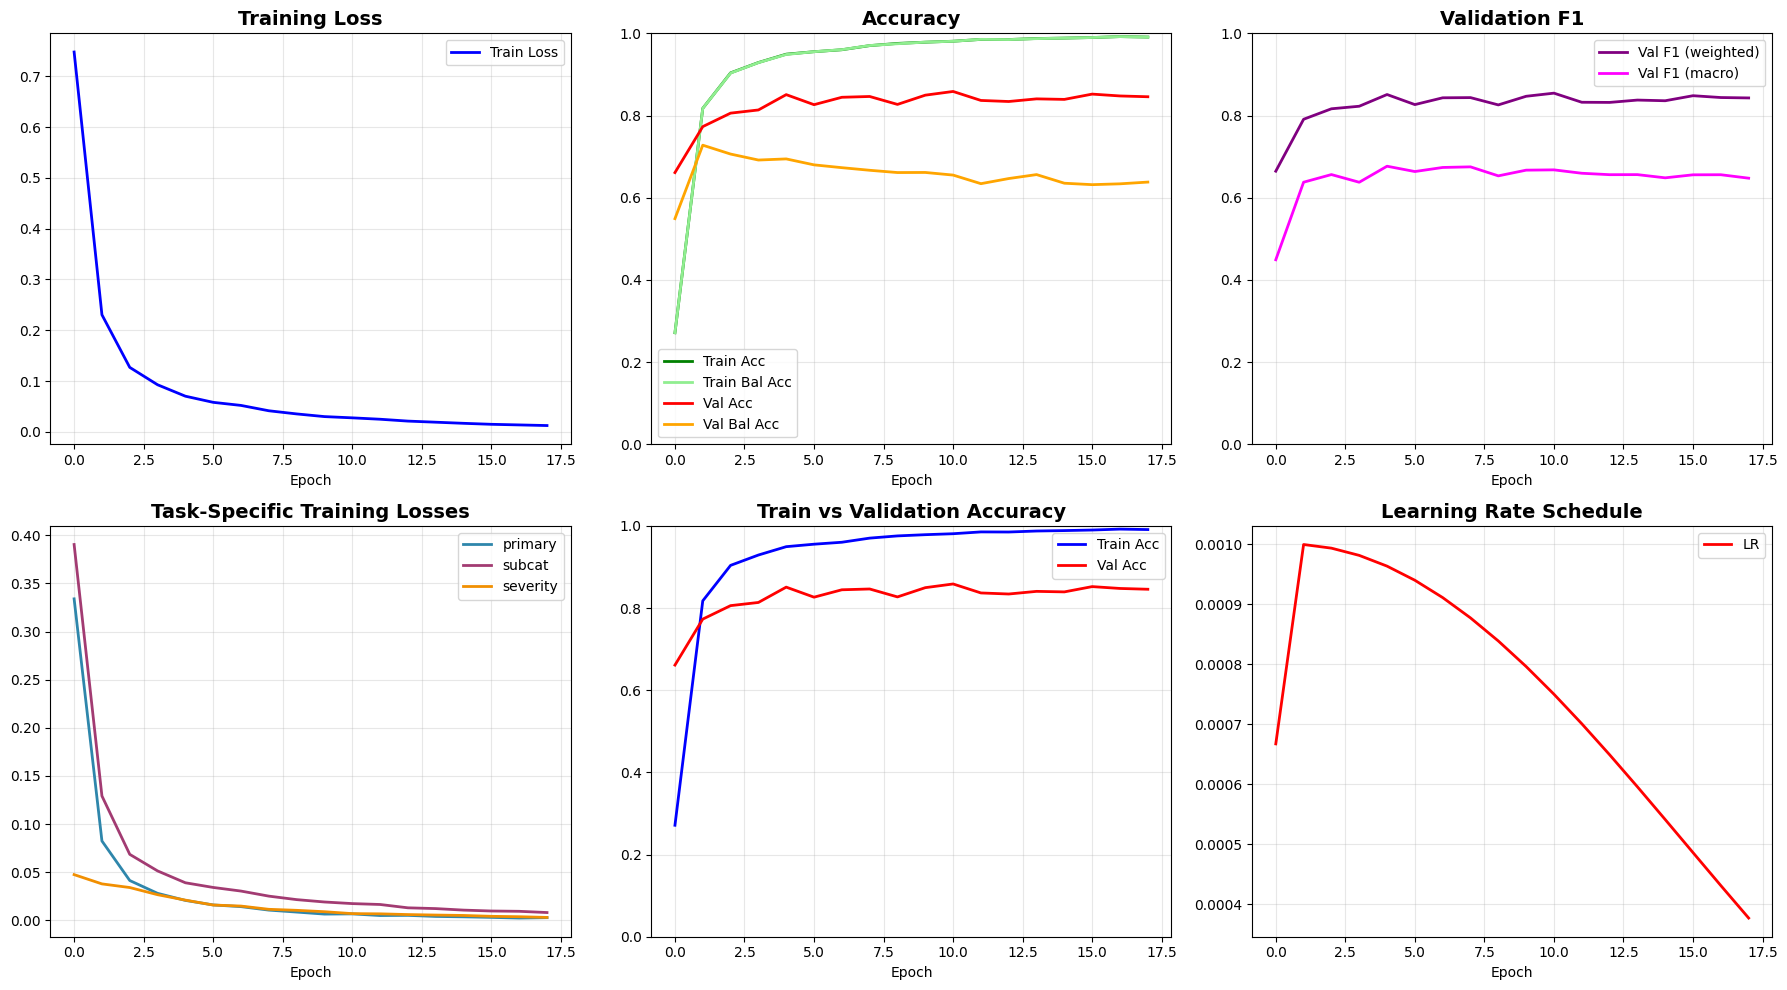

In [12]:
# ============================================================================
# CELL 12: TRAINING HISTORY VISUALIZATION
# ============================================================================
def plot_training_history(train_history, val_history, save_path=None):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', lw=2, color='blue')
    axes[0, 0].set_title('Training Loss', fontsize=14, fontweight='bold')

    axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', lw=2, color='green')
    axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', lw=2, color='lightgreen')
    axes[0, 1].plot([h['accuracy'] for h in val_history], label='Val Acc', lw=2, color='red')
    axes[0, 1].plot([h['balanced_accuracy'] for h in val_history], label='Val Bal Acc', lw=2, color='orange')
    axes[0, 1].set_title('Accuracy', fontsize=14, fontweight='bold')
    axes[0, 1].set_ylim(0, 1)

    axes[0, 2].plot([h['f1_weighted'] for h in val_history], label='Val F1 (weighted)', lw=2, color='purple')
    axes[0, 2].plot([h['f1_macro'] for h in val_history], label='Val F1 (macro)', lw=2, color='magenta')
    axes[0, 2].set_title('Validation F1', fontsize=14, fontweight='bold')
    axes[0, 2].set_ylim(0, 1)

    for task, color in zip(['primary', 'subcat', 'severity'], ['#2E86AB', '#A23B72', '#F18F01']):
        axes[1, 0].plot([h['task_losses'][task] for h in train_history], label=task, lw=2, color=color)
    axes[1, 0].set_title('Task-Specific Training Losses', fontsize=14, fontweight='bold')

    axes[1, 1].plot([h['acc'] for h in train_history], label='Train Acc', lw=2, color='blue')
    axes[1, 1].plot([h['accuracy'] for h in val_history], label='Val Acc', lw=2, color='red')
    axes[1, 1].set_title('Train vs Validation Accuracy', fontsize=14, fontweight='bold')
    axes[1, 1].set_ylim(0, 1)

    axes[1, 2].plot([h['lr'] for h in train_history], label='LR', lw=2, color='red')
    axes[1, 2].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')

    for ax in axes.flat:
        ax.set_xlabel('Epoch')
        ax.grid(True, alpha=0.3)
        if ax.get_legend_handles_labels()[0]:
            ax.legend()

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_training_history(
    train_history, val_history,
    save_path=f"{Config.VISUALIZATION_DIR}/training_history.png"
)

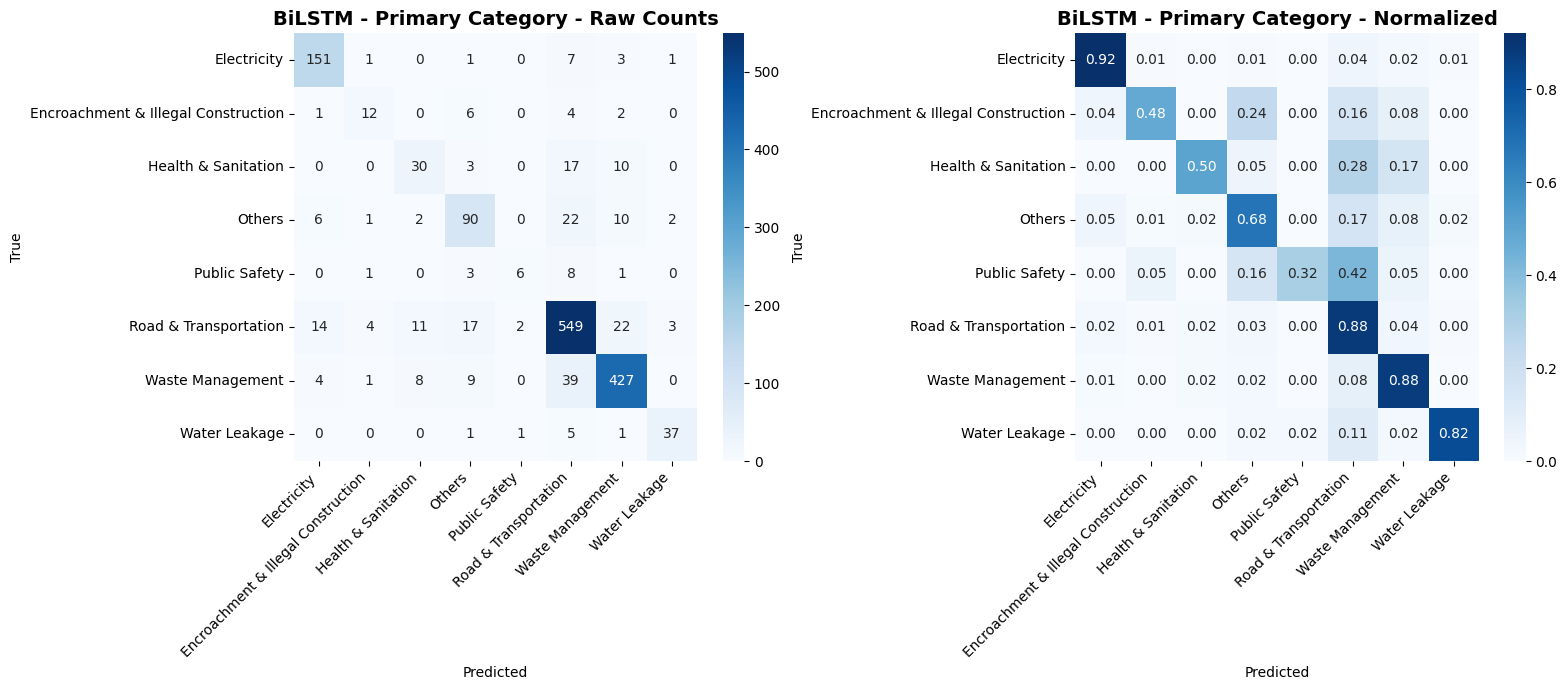

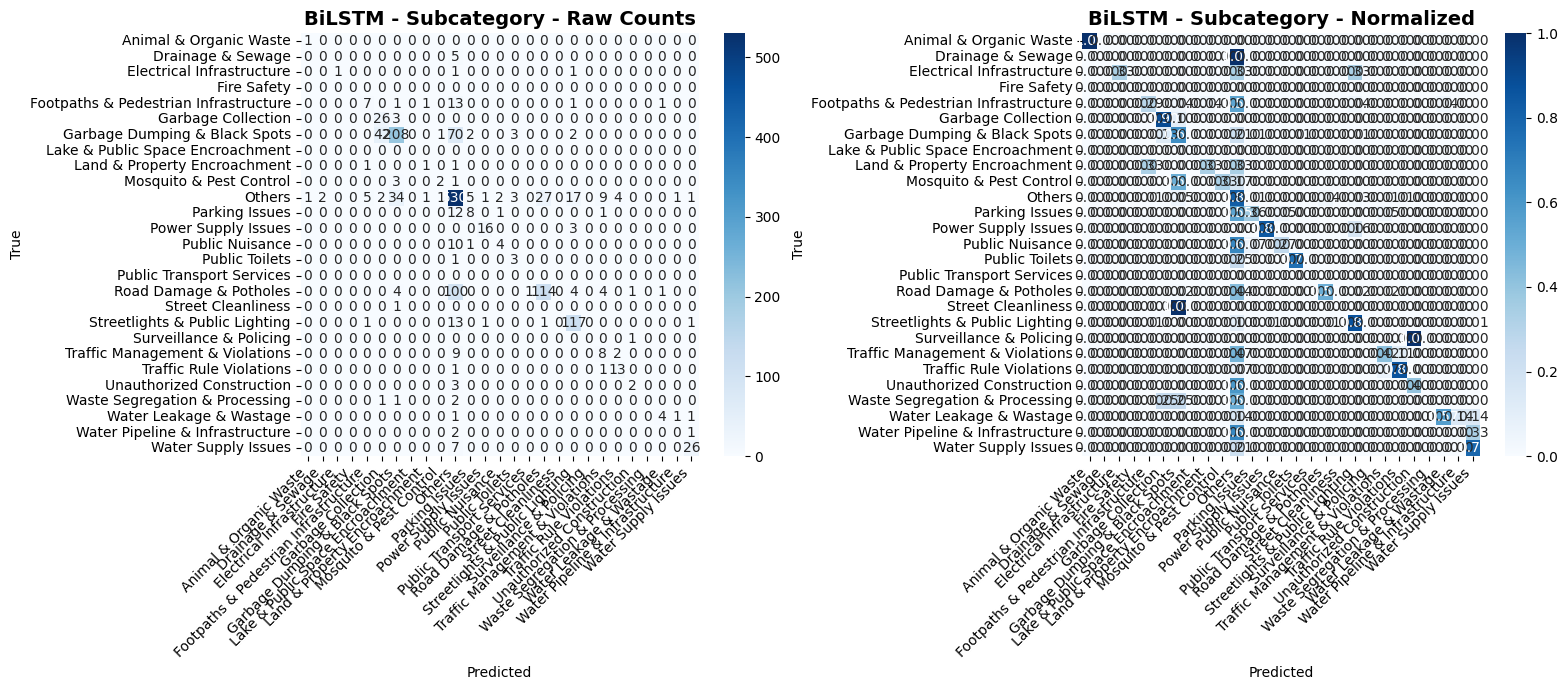

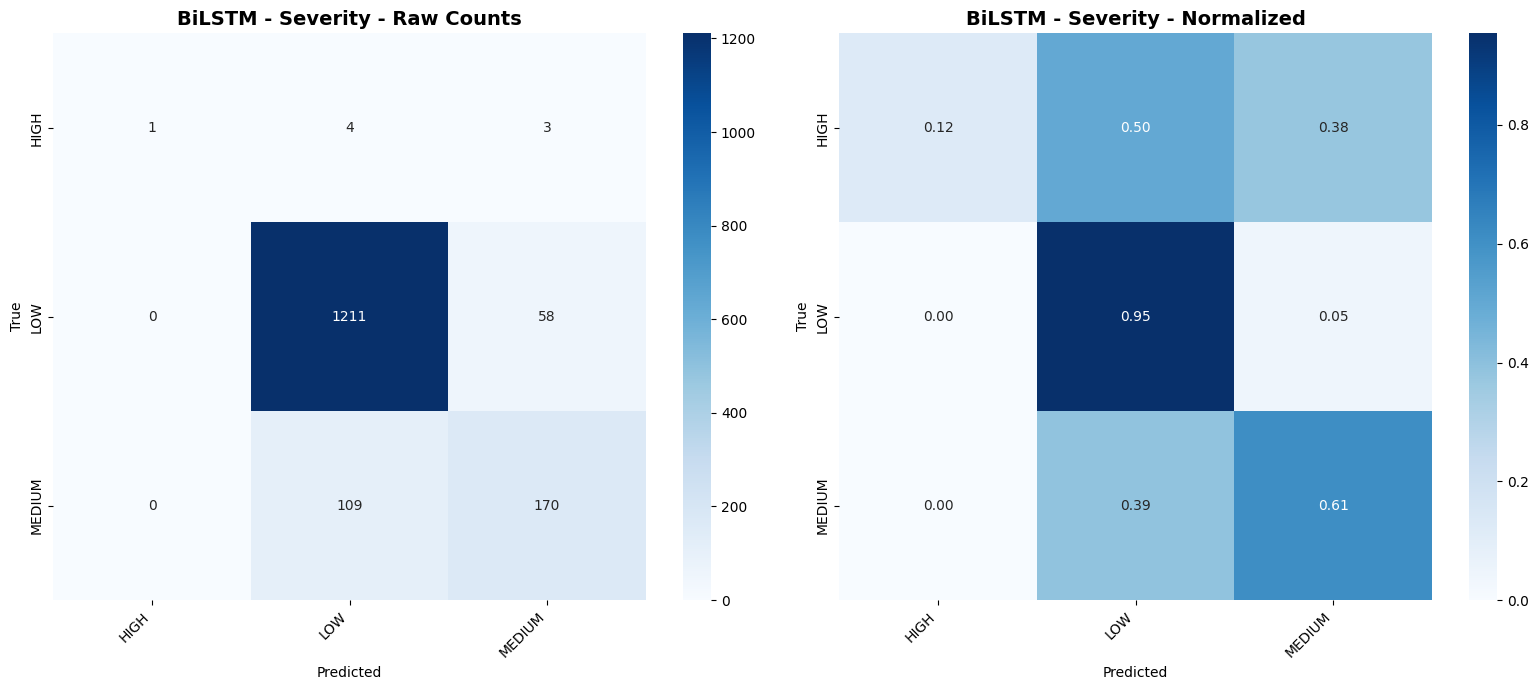

✅ Confusion matrices saved to: bilstm_results/visualizations


In [13]:
# ============================================================================
# CELL 13: CONFUSION MATRICES (all three tasks)
# ============================================================================
def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    labels = list(range(len(class_names)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    with np.errstate(divide='ignore', invalid='ignore'):
        cm_norm = np.nan_to_num(cm.astype(float) / cm.sum(axis=1, keepdims=True))

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names,
                yticklabels=class_names, ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names,
                yticklabels=class_names, ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    for ax in axes:
        ax.set_xlabel('Predicted')
        ax.set_ylabel('True')
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

task_names = {
    'primary': ('Primary Category', preprocessor.le_primary.classes_),
    'subcat': ('Subcategory', preprocessor.le_subcat.classes_),
    'severity': ('Severity', preprocessor.le_severity.classes_),
}
for task, (title, names) in task_names.items():
    plot_confusion_matrix(
        test_out["label"][task], test_out["pred"][task], names,
        f'BiLSTM - {title}',
        save_path=f"{Config.VISUALIZATION_DIR}/confusion_{task}.png"
    )
print(f"✅ Confusion matrices saved to: {Config.VISUALIZATION_DIR}")

In [14]:
# ============================================================================
# CELL 14: CLASSIFICATION REPORTS (all three tasks)
# ============================================================================
report_path = f"{Config.RESULTS_DIR}/classification_report.txt"
with open(report_path, 'w') as f:
    f.write("CLASSIFICATION REPORTS - BiLSTM\n" + "=" * 80 + "\n\n")
    for task, (title, names) in task_names.items():
        report = classification_report(
            test_out["label"][task], test_out["pred"][task],
            labels=list(range(len(names))), target_names=names,
            digits=4, zero_division=0,
        )
        print("\n" + "=" * 80)
        print(f"CLASSIFICATION REPORT - {title.upper()} (BiLSTM)")
        print("=" * 80)
        print(report)
        f.write(f"{title.upper()}\n{'-' * 60}\n{report}\n\n")
print(f"✅ Classification reports saved to: {report_path}")


CLASSIFICATION REPORT - PRIMARY CATEGORY (BiLSTM)
                                     precision    recall  f1-score   support

                        Electricity     0.8580    0.9207    0.8882       164
Encroachment & Illegal Construction     0.6000    0.4800    0.5333        25
                Health & Sanitation     0.5882    0.5000    0.5405        60
                             Others     0.6923    0.6767    0.6844       133
                      Public Safety     0.6667    0.3158    0.4286        19
              Road & Transportation     0.8433    0.8826    0.8625       622
                   Waste Management     0.8971    0.8750    0.8859       488
                      Water Leakage     0.8605    0.8222    0.8409        45

                           accuracy                         0.8368      1556
                          macro avg     0.7508    0.6841    0.7081      1556
                       weighted avg     0.8334    0.8368    0.8337      1556


CLASSIFICATION REPORT

Applying t-SNE to 1556 points...


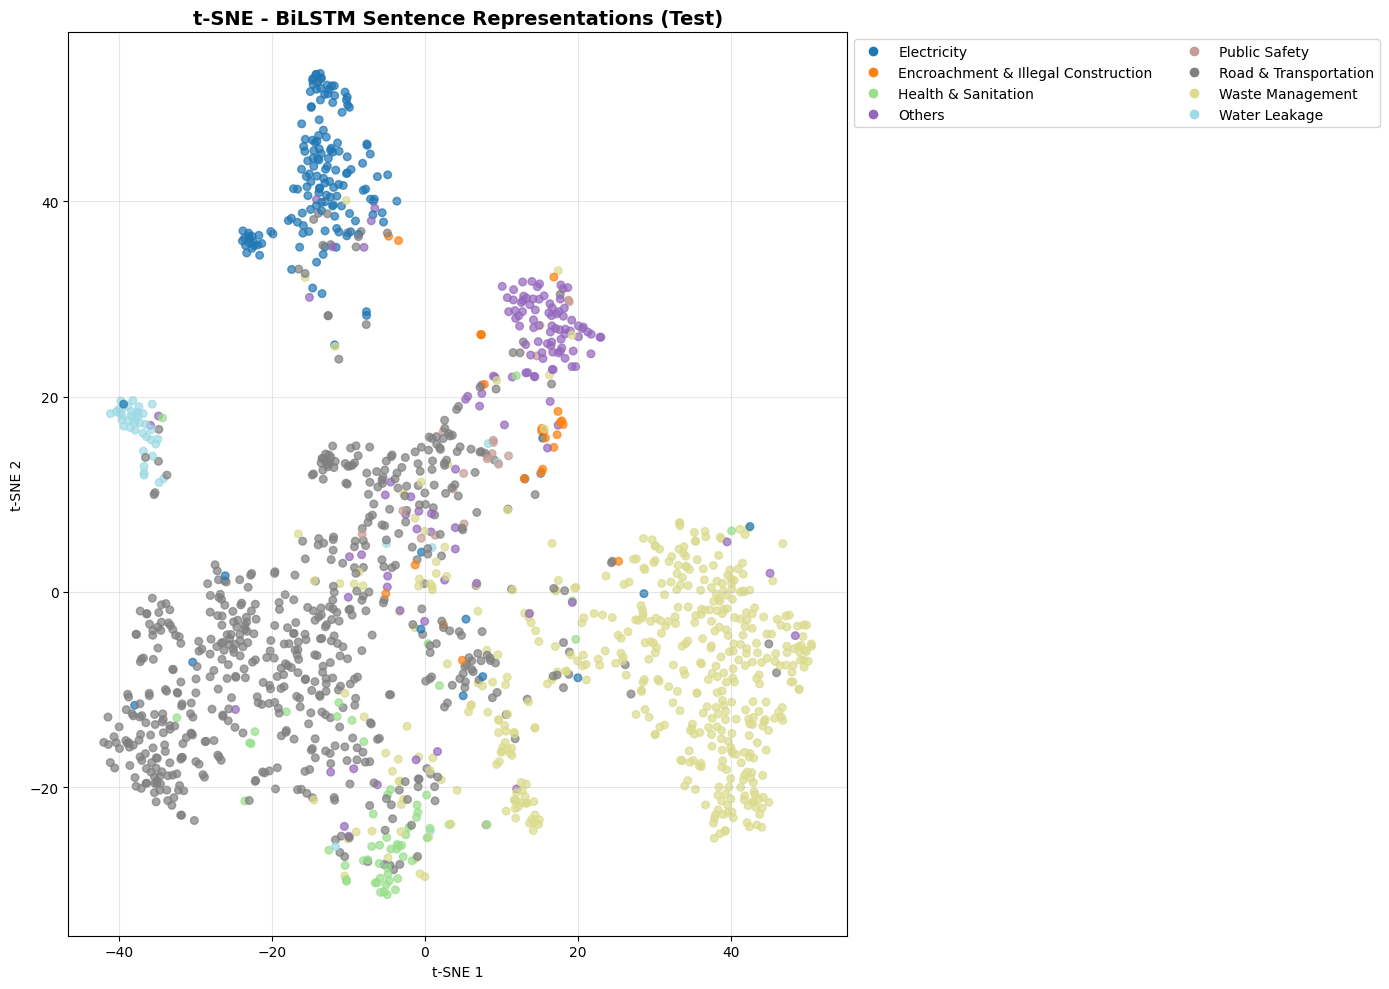

In [15]:
# ============================================================================
# CELL 15: t-SNE OF SENTENCE REPRESENTATIONS
# ============================================================================
def plot_tsne_embeddings(embeddings, labels, class_names, title, save_path=None, max_points=2000):
    if len(embeddings) > max_points:
        idx = np.random.RandomState(Config.SEED).choice(len(embeddings), max_points, replace=False)
        embeddings, labels = embeddings[idx], labels[idx]

    print(f"Applying t-SNE to {embeddings.shape[0]} points...")
    tsne = TSNE(n_components=2, random_state=Config.SEED, perplexity=30, max_iter=1000,
                init='pca', learning_rate='auto')
    xy = tsne.fit_transform(embeddings)

    fig, ax = plt.subplots(figsize=(14, 10))
    cmap = plt.get_cmap('tab20', len(class_names))
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap=cmap, vmin=-0.5,
                    vmax=len(class_names) - 0.5, alpha=0.7, s=30)
    handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(i),
                          label=n, markersize=8) for i, n in enumerate(class_names)]
    ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1, 1), ncol=2)
    ax.set_title(f't-SNE - {title}', fontsize=14, fontweight='bold')
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_tsne_embeddings(
    test_out["embeddings"], test_out["label"]["primary"],
    preprocessor.le_primary.classes_, 'BiLSTM Sentence Representations (Test)',
    save_path=f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png"
)

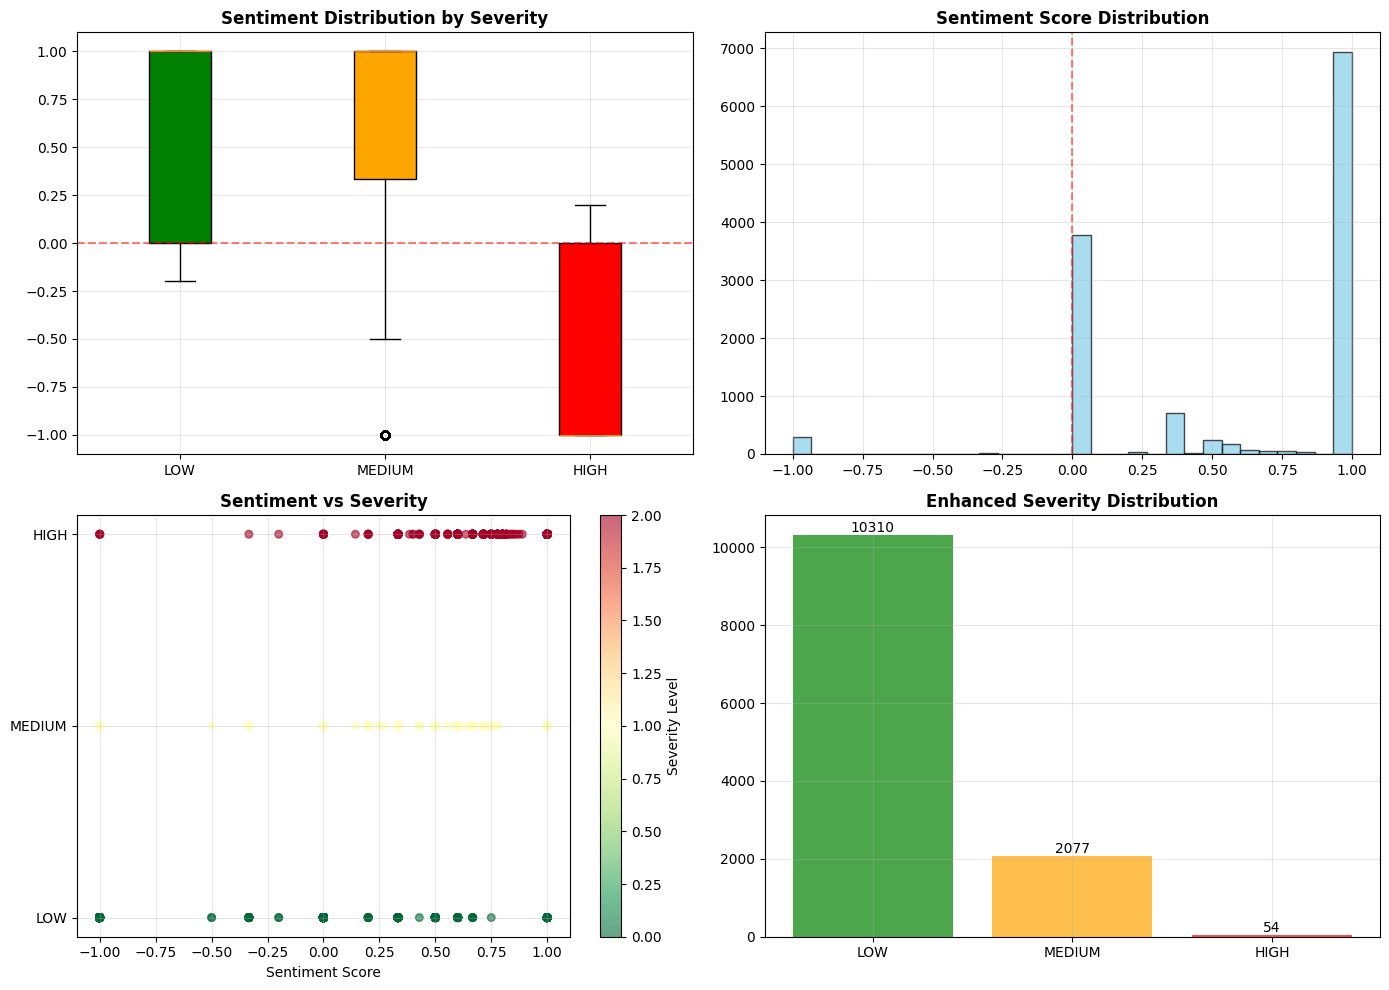

In [16]:
# ============================================================================
# CELL 16: SENTIMENT ANALYSIS VISUALIZATION (unchanged in purpose)
# ============================================================================
def plot_sentiment_analysis(df, save_path=None):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    order = ['LOW', 'MEDIUM', 'HIGH']
    colors = ['green', 'orange', 'red']

    groups = [df.loc[df['enhanced_severity_label'] == s, 'sentiment_score'].values for s in order]
    bp = axes[0, 0].boxplot(groups, patch_artist=True)
    axes[0, 0].set_xticks([1, 2, 3], order)
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
    axes[0, 0].axhline(0, color='red', ls='--', alpha=0.5)
    axes[0, 0].set_title('Sentiment Distribution by Severity', fontweight='bold')

    axes[0, 1].hist(df['sentiment_score'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    axes[0, 1].axvline(0, color='red', ls='--', alpha=0.5)
    axes[0, 1].set_title('Sentiment Score Distribution', fontweight='bold')

    sc = axes[1, 0].scatter(df['sentiment_score'], df['severity_encoded'],
                            c=df['severity_encoded'], cmap='RdYlGn_r', alpha=0.6, s=30)
    axes[1, 0].set_yticks([0, 1, 2], order)
    axes[1, 0].set_xlabel('Sentiment Score')
    axes[1, 0].set_title('Sentiment vs Severity', fontweight='bold')
    plt.colorbar(sc, label='Severity Level', ax=axes[1, 0])

    counts = [int((df['enhanced_severity_label'] == s).sum()) for s in order]
    bars = axes[1, 1].bar(order, counts, color=colors, alpha=0.7)
    for b, c in zip(bars, counts):
        axes[1, 1].text(b.get_x() + b.get_width() / 2, b.get_height(), str(c), ha='center', va='bottom')
    axes[1, 1].set_title('Enhanced Severity Distribution', fontweight='bold')

    for ax in axes.flat:
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_sentiment_analysis(train_df, save_path=f"{Config.VISUALIZATION_DIR}/sentiment_analysis.png")

In [17]:
# ============================================================================
# CELL 17: IMBALANCE IMPACT ANALYSIS (primary task, test set)
# ============================================================================
def analyze_imbalance_impact(y_true, y_pred, class_names):
    n = len(class_names)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(n)), average=None, zero_division=0
    )
    df_res = pd.DataFrame({
        'class': class_names, 'precision': precision, 'recall': recall,
        'f1': f1, 'support': support,
    }).sort_values('support', ascending=False).reset_index(drop=True)

    print("\nPer-class performance (sorted by support):")
    print(df_res.to_string(index=False))

    if np.std(df_res['support']) > 0 and np.std(df_res['f1']) > 0:
        corr, p = pearsonr(df_res['support'], df_res['f1'])
        print(f"\nPearson correlation (support vs F1): {corr:.4f} (p = {p:.4f})")
    else:
        print("\nPearson correlation skipped: constant support or F1 values.")
    return df_res

df_imbalance = analyze_imbalance_impact(
    test_out["label"]["primary"], test_out["pred"]["primary"],
    preprocessor.le_primary.classes_
)
df_imbalance.to_csv(f"{Config.RESULTS_DIR}/imbalance_impact_analysis.csv", index=False)
print(f"✅ Saved to {Config.RESULTS_DIR}/imbalance_impact_analysis.csv")


Per-class performance (sorted by support):
                              class  precision   recall       f1  support
              Road & Transportation   0.843318 0.882637 0.862529      622
                   Waste Management   0.897059 0.875000 0.885892      488
                        Electricity   0.857955 0.920732 0.888235      164
                             Others   0.692308 0.676692 0.684411      133
                Health & Sanitation   0.588235 0.500000 0.540541       60
                      Water Leakage   0.860465 0.822222 0.840909       45
Encroachment & Illegal Construction   0.600000 0.480000 0.533333       25
                      Public Safety   0.666667 0.315789 0.428571       19

Pearson correlation (support vs F1): 0.6491 (p = 0.0816)
✅ Saved to bilstm_results/results/imbalance_impact_analysis.csv


In [18]:
# ============================================================================
# CELL 18: INFERENCE
# ============================================================================
@torch.no_grad()
def predict_complaint(text, model, vocab, preprocessor, device):
    """Predict primary category, subcategory and severity for one complaint."""
    sentiment = float(preprocessor.compute_sentiment_score(text))

    seq = vocab.transform(subword_ids([text]))[0]
    ids, mask = pad_sequences([seq], Config.MAX_LENGTH)

    model.eval()
    p1, p2, p3 = model(
        torch.from_numpy(ids).to(device),
        torch.from_numpy(mask).to(device),
        torch.tensor([sentiment], dtype=torch.float, device=device),
    )

    def decode(logits, le):
        probs = torch.softmax(logits, dim=1)[0]
        idx = int(torch.argmax(probs))
        return le.inverse_transform([idx])[0], float(probs[idx])

    primary, c1 = decode(p1, preprocessor.le_primary)
    subcat, c2 = decode(p2, preprocessor.le_subcat)
    severity, c3 = decode(p3, preprocessor.le_severity)
    return {
        'primary_category': primary, 'subcategory': subcat, 'severity': severity,
        'sentiment_score': sentiment,
        'confidence': {'primary': c1, 'subcategory': c2, 'severity': c3},
    }

test_texts = [
    "Garbage not collected in my area for last 5 days. Bad smell everywhere! Very urgent!",
    "There is a very big pothole on the main road, my car got damaged",
    "Water leakage in our building, please fix immediately, it's an emergency!",
    "Thank you for fixing the streetlight in our area, it's working now.",
    "Streetlights not working on my street for 3 days, very dangerous at night",
    "The garbage bins are overflowing and spreading foul smell in the entire colony",
]

print("\n" + "=" * 70)
print("INFERENCE DEMO - BiLSTM")
print("=" * 70)
for i, text in enumerate(test_texts, 1):
    r = predict_complaint(text, model, vocab, preprocessor, Config.DEVICE)
    print(f"\nText {i}: {text}")
    print("-" * 50)
    print(f"Primary Category: {r['primary_category']} ({r['confidence']['primary']:.3f})")
    print(f"Subcategory: {r['subcategory']} ({r['confidence']['subcategory']:.3f})")
    print(f"Severity: {r['severity']} ({r['confidence']['severity']:.3f})")
    print(f"Sentiment Score: {r['sentiment_score']:.3f}")


INFERENCE DEMO - BiLSTM

Text 1: Garbage not collected in my area for last 5 days. Bad smell everywhere! Very urgent!
--------------------------------------------------
Primary Category: Waste Management (0.822)
Subcategory: Garbage Collection (0.730)
Severity: MEDIUM (0.867)
Sentiment Score: 1.000

Text 2: There is a very big pothole on the main road, my car got damaged
--------------------------------------------------
Primary Category: Road & Transportation (0.804)
Subcategory: Road Damage & Potholes (0.730)
Severity: LOW (0.556)
Sentiment Score: 1.000

Text 3: Water leakage in our building, please fix immediately, it's an emergency!
--------------------------------------------------
Primary Category: Water Leakage (0.817)
Subcategory: Water Leakage & Wastage (0.938)
Severity: MEDIUM (0.948)
Sentiment Score: 1.000

Text 4: Thank you for fixing the streetlight in our area, it's working now.
--------------------------------------------------
Primary Category: Electricity (0.896)
Subc

In [19]:
# ============================================================================
# CELL 19: SUMMARY REPORT (printed and saved)
# ============================================================================
def generate_summary_report():
    lines = []
    add = lines.append
    add("=" * 80)
    add("BiLSTM MULTI-TASK COMPLAINT CLASSIFICATION - SUMMARY REPORT")
    add("=" * 80)

    add("\n1. DATASET STATISTICS")
    add(f"   Training samples: {len(train_df)}")
    add(f"   Validation samples: {len(dev_df)}")
    add(f"   Test samples: {len(test_df)}")
    add(f"   Vocabulary size: {vocab.size:,} (min_freq={Config.MIN_FREQ})")
    add(f"   Primary categories: {n_primary} | Subcategories: {n_subcat} | Severity levels: {n_severity}")

    add("\n2. MODEL ARCHITECTURE")
    add(f"   Encoder: BiLSTM, {Config.LSTM_LAYERS} layers x {Config.LSTM_HIDDEN} per direction")
    add(f"   Embedding dim: {emb_dim} (pretrained init: {Config.USE_PRETRAINED_EMBEDDINGS})")
    add(f"   Pooling: masked mean + max -> {model.rep_dim}-dim sentence vector")
    add(f"   Total parameters: {sum(p.numel() for p in model.parameters()):,}")
    add(f"   Dropout: {Config.DROPOUT} | LSTM dropout: {Config.LSTM_DROPOUT} | Max length: {Config.MAX_LENGTH}")

    add("\n3. IMBALANCE HANDLING")
    add(f"   Focal loss: {Config.USE_FOCAL_LOSS} (alpha={Config.FOCAL_ALPHA}, gamma={Config.FOCAL_GAMMA})")
    add(f"   Weighted sampler: {Config.USE_WEIGHTED_SAMPLER}")

    add("\n4. TRAINING")
    add(f"   Epochs run: {len(train_history)} / {Config.EPOCHS} (best epoch: {early_stopping.best_epoch + 1})")
    add(f"   Batch size: {Config.BATCH_SIZE} | LR: {Config.LEARNING_RATE} | Weight decay: {Config.WEIGHT_DECAY}")
    add(f"   Best validation F1 (weighted): {best_val_f1:.4f}")

    add("\n5. TEST SET PERFORMANCE")
    for task, m in test_metrics.items():
        add(f"\n   {task.upper()}:")
        for name, value in m.items():
            add(f"     {name}: {value:.4f}")

    add("\n6. SAVED FILES")
    add(f"   Model: {Config.MODEL_DIR}/bilstm_multitask_model.pt")
    add(f"   Best checkpoint: {best_path}")
    add(f"   Encoders and vocab: {Config.MODEL_DIR}/")
    add(f"   Reports: {Config.RESULTS_DIR}/")
    add(f"   Visualizations: {Config.VISUALIZATION_DIR}/")
    add("=" * 80)

    text = "\n".join(lines)
    print(text)
    with open(f"{Config.RESULTS_DIR}/summary_report.txt", "w") as f:
        f.write(text + "\n")

generate_summary_report()
print(f"\n📁 All results saved to: {Config.BASE_DIR}")

BiLSTM MULTI-TASK COMPLAINT CLASSIFICATION - SUMMARY REPORT

1. DATASET STATISTICS
   Training samples: 12441
   Validation samples: 1555
   Test samples: 1556
   Vocabulary size: 14,839 (min_freq=2)
   Primary categories: 8 | Subcategories: 27 | Severity levels: 3

2. MODEL ARCHITECTURE
   Encoder: BiLSTM, 2 layers x 256 per direction
   Embedding dim: 768 (pretrained init: True)
   Pooling: masked mean + max -> 1024-dim sentence vector
   Total parameters: 15,113,513
   Dropout: 0.3 | LSTM dropout: 0.3 | Max length: 128

3. IMBALANCE HANDLING
   Focal loss: True (alpha=0.25, gamma=2.0)
   Weighted sampler: True

4. TRAINING
   Epochs run: 18 / 30 (best epoch: 11)
   Batch size: 32 | LR: 0.001 | Weight decay: 0.0001
   Best validation F1 (weighted): 0.8544

5. TEST SET PERFORMANCE

   PRIMARY:
     accuracy: 0.8368
     balanced_accuracy: 0.6841
     precision_weighted: 0.8334
     recall_weighted: 0.8368
     f1_macro: 0.7081
     f1_weighted: 0.8337
     cohen_kappa: 0.7718
     mcc